In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
results = [
    {  "model": "VAE_64",
            "val_loss_mean": 0.00028665321588050574,
            "val_loss_std": 2.02309144523507e-05,
            "val_mse_mean": 0.00021805333235533909,
            "val_mse_std": 1.98211668992076e-05,
            "val_kl_mean": 9.912683296203614,
            "val_kl_std": 0.5189131387227927,
            "val_r2_mean": 0.5860942482948304,
            "val_r2_std": 0.03807775968825431,
        },
    {
        "model": "VAE_128",
        "val_loss_mean": 0.0002721964381635189,
        "val_loss_std": 1.0016386246198838e-05,
        "val_mse_mean": 0.00020341035997262225,
        "val_mse_std": 1.2014736168156983e-05,
        "val_kl_mean": 9.939588069915771,
        "val_kl_std": 0.3252049152689851,
        "val_r2_mean": 0.6139713943004608,
        "val_r2_std": 0.021766786677005247,
    },
    {
        "model": "VAE_256",
        "val_loss_mean": 0.00027683964290190486,
        "val_loss_std": 1.9451398735410643e-05,
        "val_mse_mean": 0.00020617884292732923,
        "val_mse_std": 1.755784727859384e-05,
        "val_kl_mean": 10.210485172271728,
        "val_kl_std": 0.4286939205374992,
        "val_r2_mean": 0.6087620437145234,
        "val_r2_std": 0.03212511983348359,
    },
]

df = pd.DataFrame(results).set_index("model")
df

,val_loss_mean,val_loss_std,val_mse_mean,val_mse_std,val_kl_mean,val_kl_std,val_r2_mean,val_r2_std
model,,,,,,,,
VAE_64,0.000287,0.000020,0.000218,0.000020,9.912683,0.518913,0.586094,0.038078
VAE_128,0.000272,0.000010,0.000203,0.000012,9.939588,0.325205,0.613971,0.021767
VAE_256,0.000277,0.000019,0.000206,0.000018,10.210485,0.428694,0.608762,0.032125


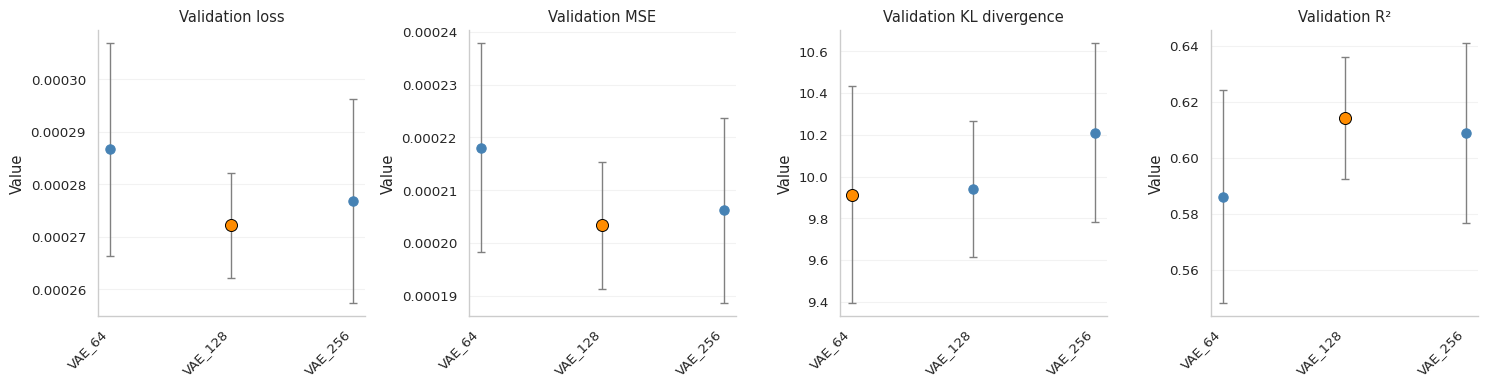

In [9]:
metrics = {
    "Validation loss": ("val_loss_mean", "val_loss_std", "min"),
    "Validation MSE": ("val_mse_mean", "val_mse_std", "min"),
    "Validation KL divergence": ("val_kl_mean", "val_kl_std", "min"),
    "Validation R²": ("val_r2_mean", "val_r2_std", "max"),
}

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, (title, (mean_col, std_col, criterion)) in zip(axes.flat, metrics.items()):
    x = np.arange(len(df))
    means = df[mean_col].values
    stds = df[std_col].values
    best_idx = np.nanargmin(means) if criterion == "min" else np.nanargmax(means) #type:ignore

    # All models
    ax.scatter(
        x, means,
        s=45,
        color="steelblue",
        zorder=3,
        label="Other models"
    )

    # Error bars
    ax.errorbar(
        x, means,
        yerr=stds,
        fmt="none",
        capsize=3,
        elinewidth=1,
        capthick=1,
        color="grey",
        zorder=2
    )

    # Best model
    ax.scatter(
        x[best_idx],
        means[best_idx],
        s=75,
        color="darkorange",
        edgecolor="black",
        linewidth=0.7,
        zorder=4,
        label="Best model"
    )

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(df.index, rotation=45, ha="right")
    ax.set_xlabel("")
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()

#plt.savefig("validation_metrics.pdf", bbox_inches="tight")
#plt.savefig("validation_metrics.png", bbox_inches="tight", dpi=300)

plt.show()

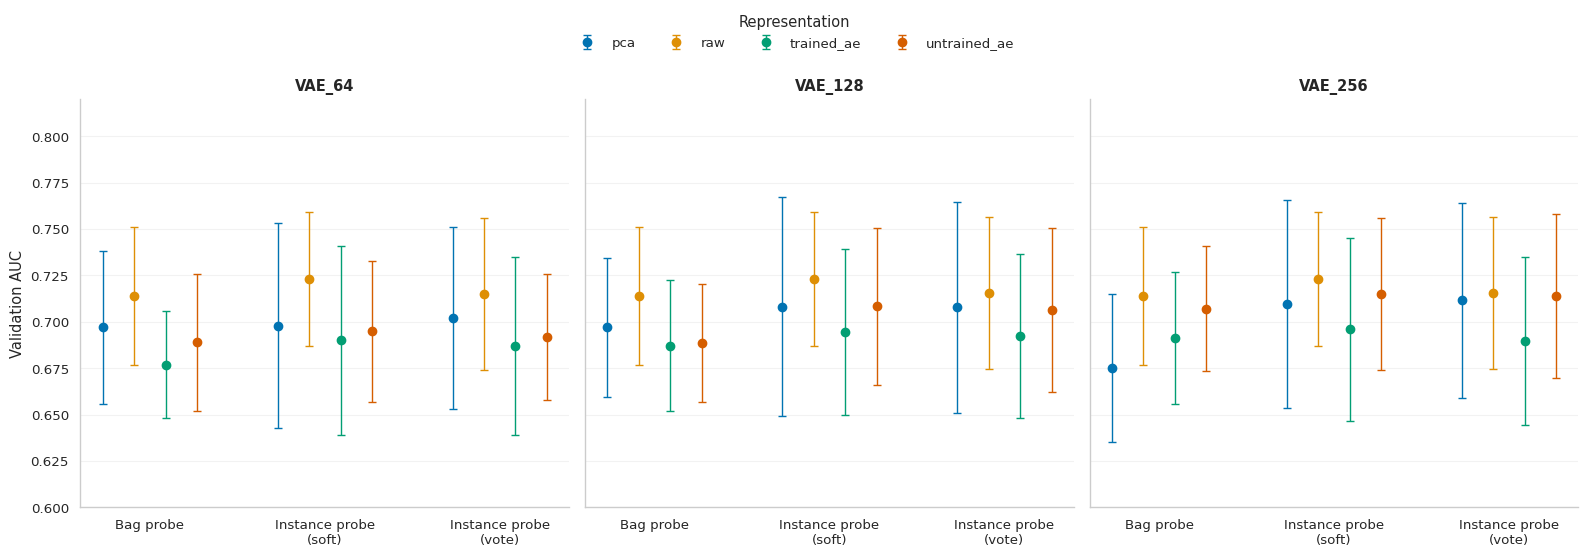

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = [
    # Representation, Method,
    # VAE_64 mean, std, VAE_128 mean, std, VAE_256 mean, std

    ("pca", "LinearBagProbe",
     0.697, 0.041, 0.6971668, 0.0374204, 0.6751516, 0.0396224),

    ("pca", "LinearInstanceProbeBagLabels_soft",
     0.698, 0.055, 0.7081366, 0.0590370, 0.7096584, 0.0558249),

    ("pca", "LinearInstanceProbeBagLabels_vote",
     0.702, 0.049, 0.7078486, 0.0567552, 0.7115238, 0.0524206),

    ("raw", "LinearBagProbe",
     0.714, 0.037, 0.7138744, 0.0373912, 0.7138744, 0.0373912),

    ("raw", "LinearInstanceProbeBagLabels_soft",
     0.723, 0.036, 0.7230350, 0.0361659, 0.7230350, 0.0361659),

    ("raw", "LinearInstanceProbeBagLabels_vote",
     0.715, 0.041, 0.7154958, 0.0407385, 0.7154958, 0.0407385),

    ("trained_ae", "LinearBagProbe",
     0.677, 0.029, 0.6872270, 0.0352040, 0.6913682, 0.0355566),

    ("trained_ae", "LinearInstanceProbeBagLabels_soft",
     0.690, 0.051, 0.6944495, 0.0445195, 0.6959306, 0.0494699),

    ("trained_ae", "LinearInstanceProbeBagLabels_vote",
     0.687, 0.048, 0.6924765, 0.0441135, 0.6896597, 0.0453631),

    ("untrained_ae", "LinearBagProbe",
     0.689, 0.037, 0.6885619, 0.0317553, 0.7071183, 0.0336138),

    ("untrained_ae", "LinearInstanceProbeBagLabels_soft",
     0.695, 0.038, 0.7083038, 0.0421667, 0.7148345, 0.0408267),

    ("untrained_ae", "LinearInstanceProbeBagLabels_vote",
     0.692, 0.034, 0.7062967, 0.0443578, 0.7137809, 0.0443012),
]

columns = [
    "Representation", "Method",
    "VAE_64_mean", "VAE_64_std",
    "VAE_128_mean", "VAE_128_std",
    "VAE_256_mean", "VAE_256_std"
]

probe_df = pd.DataFrame(data, columns=columns)

# Convert to long format
plot_dfs = []

for model in ["VAE_64", "VAE_128", "VAE_256"]:
    temp = probe_df[
        ["Representation", "Method", f"{model}_mean", f"{model}_std"]
    ].rename(columns={
        f"{model}_mean": "Mean",
        f"{model}_std": "Std"
    })

    temp["Model"] = model
    plot_dfs.append(temp)

plot_df = pd.concat(plot_dfs, ignore_index=True)

# Publication style
sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.1
)

representations = [
    "pca",
    "raw",
    "trained_ae",
    "untrained_ae"
]

methods = [
    "LinearBagProbe",
    "LinearInstanceProbeBagLabels_soft",
    "LinearInstanceProbeBagLabels_vote"
]

method_labels = [
    "Bag probe",
    "Instance probe\n(soft)",
    "Instance probe\n(vote)"
]

palette = dict(zip(
    representations,
    sns.color_palette("colorblind", n_colors=4)
))

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=True
)

width = 0.18
x = np.arange(len(methods))

for ax, model in zip(axes, ["VAE_64", "VAE_128", "VAE_256"]):

    subset_model = plot_df[plot_df["Model"] == model]

    for i, representation in enumerate(representations):

        subset = (
            subset_model[
                subset_model["Representation"] == representation
            ]
            .set_index("Method")
            .loc[methods]
        )

        offset = (i - 1.5) * width

        ax.errorbar(
            x + offset,
            subset["Mean"],
            yerr=subset["Std"],
            fmt="o",
            markersize=6,
            capsize=3,
            elinewidth=1,
            capthick=1,
            color=palette[representation],
            label=representation,
            zorder=3
        )

    ax.set_title(model, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(method_labels)
    ax.set_xlabel("")
    ax.set_ylim(0.60, 0.82)

    ax.grid(axis="y", alpha=0.25)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Validation AUC")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles[:4],
    labels[:4],
    title="Representation",
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.12),
    ncol=4
)

sns.despine()
plt.tight_layout()

#plt.savefig("vae_probe_comparison.pdf", bbox_inches="tight")
#plt.savefig("vae_probe_comparison.png", dpi=300, bbox_inches="tight")

plt.show()